# 03 · Point-in-time panel
The stock-month panel and the checks that it uses no future information. The same invariants are asserted in `tests/test_panel.py`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from src.utils.config import path
T = path('results') / 'tables'
from src.features.timing import risk_first_month
p = pd.read_parquet(path('processed')/'panel.parquet'); print(p.shape)

(297717, 123)


In [2]:
x = p[p.filing_date.notna()]
lag = (pd.PeriodIndex(x.month).asi8 - pd.PeriodIndex(x.filing_month).asi8)
print('months since filing: min', lag.min(), 'max', lag.max())
print('all signals strictly before month start:', ((x.filing_date + pd.offsets.BDay(2)) < x.month.dt.to_timestamp()).all())

months since filing: min 1 max 15
all signals strictly before month start: True


In [3]:
pd.read_csv(T/'sanity_factor_replication.csv')

,series,french,months,corr,mean_ours,mean_french
0,mom_decile_LS_ew,mom,143,0.827137,0.002818,0.002515
1,size_decile_SmB_ew,smb,143,0.843008,0.000029,0.000115
2,mom_decile_LS_ext_ew,mom,186,0.850339,0.002028,0.000011


Our own momentum and size long-shorts track Ken French's UMD and SMB closely, which validates the free price pipeline.

In [4]:
pd.read_csv(T/'return_cleaning.csv', index_col=0)

,n
lt_minus100,5
gt_1000,401
total_blanked,406
rows,799604


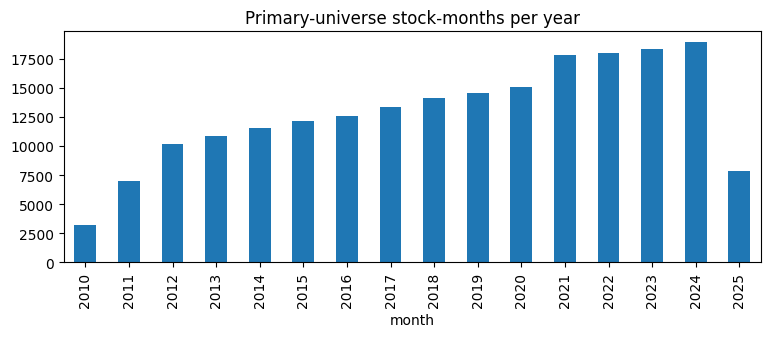

In [5]:
e = p[p.elig]; e.groupby(e.month.dt.year).size().plot(kind='bar', figsize=(9,3), title='Primary-universe stock-months per year'); plt.show()